# NESG Stage 1: layer-wise linear solubility decoding
This notebook separates completed measurements from pending ESM experiments. It reads only the frozen development cohort and saved results. No reserved-test sequences or labels, SAE features, interventions or biological-concept probes are accessed.
The phenotype is high-expression NESG soluble recovery: E∈{4,5}, S∈{4,5} versus S=0. It is not a universal, condition-independent physical solubility measurement.

In [1]:
from pathlib import Path
import sys, json, subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
here = Path.cwd()
if not (here / 'common.py').exists():
    here = here / 'nesg_primary/esm_layer_probing'
sys.path.insert(0, str(here))
from common import HERE, PROTOCOL, read_local, sha
from report import baseline_figure, layer_figure, recommendation, write_summary
data = read_local()
checks = json.loads((HERE / 'data/checks.json').read_text())
display(pd.crosstab(data.split, data.label).rename(columns={0:'Insoluble',1:'Soluble'}))
display(pd.Series(checks, name='Verified checks').to_frame())

label,Insoluble,Soluble
split,,
train,716,1645
validation,200,491


,Verified checks
proteins,3052
counts,"{'train': {'0': 716, '1': 1645}, 'validation':..."
groups,"{'train': 1090, 'validation': 364}"
min_length,50
max_length,810
X_proteins,3
reserved_count_verified_from_label_free_assignments,710
reserved_sequences_or_labels_opened,False
all_input_hashes_verified,True
sequence_hashes_verified,True


## 1. Frozen inputs and protocol
There are 2,361 training proteins (1,645 soluble / 716 insoluble) and 691 validation proteins (491 / 200). All three X-containing sequences remain unchanged; 50–810 residues fit without truncation. Stable IDs and SHA-256 values link the extraction manifest, labels, domain-level Pfam multi-memberships and MMseqs2 groups. Missing Pfam annotations never exclude proteins.
Group assignment is homology-aware, not family-disjoint: a shared Pfam domain may appear in several splits. The prospective test lock remains; test labels were historically inspected in earlier reports and are not accessed here.

In [2]:
tr = data.split.eq('train'); va = data.split.eq('validation')
assert set(data.loc[tr,'audit_cluster']).isdisjoint(data.loc[va,'audit_cluster'])
assert data.loc[tr].groupby('audit_cluster').inner_cv_fold.nunique().max() == 1
display(data.loc[tr].groupby('inner_cv_fold').agg(proteins=('record_id','size'),groups=('audit_cluster','nunique'),soluble=('label','sum')))
display(PROTOCOL)

,proteins,groups,soluble
inner_cv_fold,,,
0,471,243,314
1,446,222,321
2,424,207,281
3,590,219,411
4,430,199,318


{'model': 'facebook/esm2_t33_650M_UR50D',
 'revision': '08e4846e537177426273712802403f7ba8261b6c',
 'layers': [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33],
 'width': 1280,
 'indexing': 'hidden_states[L] for L=1..33; layer 0 is embedding output',
 'pooling': 'float32 mean of residue positions 1..length; no BOS, EOS or padding',
 'C_grid': [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0],
 'seed': 20261118,
 'bootstrap_replicates': 2000,
 'representative_layers': [8, 16, 32],
 'class_weight': None,
 'solver': 'lbfgs',
 'max_iter': 3000,
 'counts': {'train': 2361, 'validation': 691},
 'max_residues': 1022,
 'baseline': '20 standard amino-acid counts / original length plus natural log length; X not imputed',
 'SAE_available_layers': [4, 8, 12, 16, 20, 24, 28, 32, 33],
 'interprot_revision': '3ded2e51641df84d6b89f25430874e3a8eb42c24'}

## 2. Fit or reuse the prespecified linear probes
Each model is StandardScaler → L2 logistic regression, with no class balancing. C is selected by mean AUROC over the five frozen training folds, from [0.0001, 0.001, 0.01, 0.1, 1, 10]; exact ties prefer smaller C. Scaling is fitted inside every CV training fold. Selected-C fold scores are tuning estimates, not unbiased nested-CV estimates.
All final models refit on the same 2,361 training proteins. Validation labels never fit or tune C. Set `REFIT=True` to regenerate saved results. Full ESM fitting runs only if a completed and validated extraction exists; absence of embeddings cannot generate a layer result.

In [3]:
REFIT = False
activation_dir = HERE / 'activations'
have_activations = (activation_dir / 'completed.json').exists()
metrics_path = HERE / 'results/metrics.tsv'
if REFIT or not metrics_path.exists():
    command = [sys.executable, str(HERE / 'probe.py')]
    if have_activations:
        command += ['--activations', str(activation_dir)]
    subprocess.run(command, check=True)
metrics = pd.read_csv(metrics_path, sep='\t')
cv = pd.read_csv(HERE / 'results/all_cv.tsv', sep='\t')
status = json.loads((HERE / 'results/run_status.json').read_text())
assert status['protocol_sha256'] == sha(HERE / 'protocol.json')
assert status['input_manifest_sha256'] == sha(HERE / 'data/extraction_manifest.tsv')
assert status['local_labels_sha256'] == sha(HERE / 'data/local_labels.tsv')
full = (metrics.layer > 0).sum() == 33
if have_activations and not full:
    display(Markdown('**New embeddings detected. Set REFIT=True or run probe.py --activations activations to fit the 33 ESM probes.**'))
display(metrics)
display(Markdown(f"**Completed: composition baseline; {int((metrics.layer > 0).sum())}/33 ESM probes.**"))

,model,layer,C,validation_n,auroc,average_precision,auroc_low,auroc_high,ap_low,ap_high,cv_mean,cv_sd,cv_min,cv_max,bootstrap_valid,delta_vs_composition,delta_low,delta_high
0,composition,0,0.1,691,0.721629,0.84059,0.666889,0.773919,0.781432,0.891896,0.696079,0.045569,0.618179,0.735327,2000,0.0,0.0,0.0


**Completed: composition baseline; 0/33 ESM probes.**

## 3. Sequence-composition diagnostic baseline
Twenty standard amino-acid counts are divided by original sequence length, plus natural log length. X residues are retained in the denominator and not assigned to another amino acid; their unassigned mass is explicit. No aggregation or other biological-concept predictor enters the baseline.
Confidence intervals use 2,000 resamples of the 364 validation homology groups, retaining all members of each sampled group. Bootstrap draws are shared by every model for paired comparisons and do not refit models.

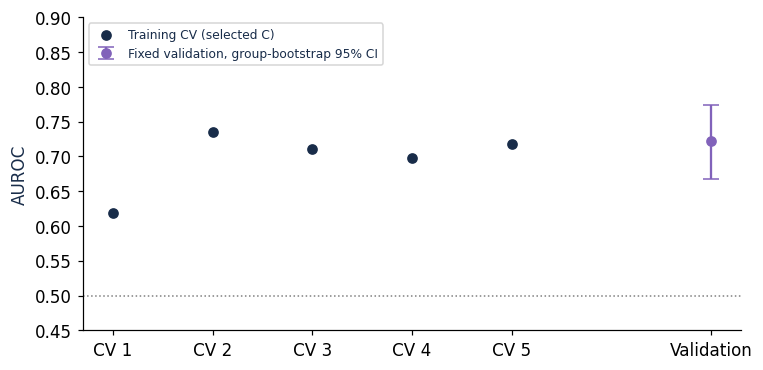

Composition validation AUROC: **0.7216** (95% CI 0.6669–0.7739); AP **0.8406**. Training-CV mean 0.6961, SD 0.0456. Validation soluble prevalence is 0.7106. Fold variation and bootstrap uncertainty limit interpretation of small performance changes.

In [4]:
baseline_figure(metrics, cv)
plt.show()
baseline = metrics[metrics.model.eq('composition')].iloc[0]
display(Markdown(f"Composition validation AUROC: **{baseline.auroc:.4f}** (95% CI {baseline.auroc_low:.4f}–{baseline.auroc_high:.4f}); AP **{baseline.average_precision:.4f}**. Training-CV mean {baseline.cv_mean:.4f}, SD {baseline.cv_sd:.4f}. Validation soluble prevalence is {data.loc[va,'label'].mean():.4f}. Fold variation and bootstrap uncertainty limit interpretation of small performance changes."))

## 4. Figure 1 — Layer-wise validation AUROC
Pointwise group-bootstrap intervals are conditional on the fitted probes and do not adjust for selecting the best of 33 layers. AUROC measures linear decodability under this protocol; it does not identify direct versus indirect encoding.

In [5]:
if full:
    layer_figure(1, metrics, cv, data.loc[va,'label'].mean()); plt.show()
    best = metrics[metrics.layer.gt(0)].sort_values('auroc', ascending=False).iloc[0]
    display(Markdown(f"Highest observed validation AUROC is layer {int(best.layer)}: {best.auroc:.4f} ({best.auroc_low:.4f}–{best.auroc_high:.4f}). This is a descriptive maximum across layers, not an independently confirmed optimum. Inspect paired differences and training-CV stability."))
else:
    display(Markdown('**Not available:** the 33-layer ESM extraction/probing has not run. No layer curve is plotted.'))

**Not available:** the 33-layer ESM extraction/probing has not run. No layer curve is plotted.

## 5. Figure 2 — Training-CV consistency
Every layer uses identical proteins and group folds. Shared fold trajectories can reflect biological differences among folds as well as sampling variability. The displayed scores reuse hyperparameter-selection folds.

In [6]:
if full:
    layer_figure(2, metrics, cv, data.loc[va,'label'].mean()); plt.show()
    display(metrics[metrics.layer.gt(0)][['layer','C','cv_mean','cv_sd','cv_min','cv_max']])
    display(Markdown('Compare depth trends across folds before treating a validation peak as reproducible. CV mean and dispersion are both retained for later layer selection.'))
else:
    display(Markdown('**Pending ESM results.** Composition CV estimates are available above.'))

**Pending ESM results.** Composition CV estimates are available above.

## 6. Figure 3 — Layer-wise average precision
Average precision depends on class prevalence. The reference is the same 491/691 validation soluble prevalence for all models; validation is never balanced.

In [7]:
if full:
    layer_figure(3, metrics, cv, data.loc[va,'label'].mean()); plt.show()
    display(Markdown('AP complements AUROC for this naturally imbalanced cohort. It is not comparable across populations with different prevalence without further qualification.'))
else:
    display(Markdown('**Pending ESM results.** No AP curve is plotted.'))

**Pending ESM results.** No AP curve is plotted.

## 7. Figure 4 — Prespecified representative layers
Layers 8, 16 and 32 span early, middle and late depth and have released InterProt checkpoints. They were fixed before ESM results. Paired intervals use identical group-bootstrap resamples for both layers. An interval crossing zero indicates the observed difference is not clearly resolved under this resampling scheme, not proof of equivalence.

In [8]:
if full:
    layer_figure(4, metrics, cv, data.loc[va,'label'].mean()); plt.show()
    display(pd.read_csv(HERE / 'results/representative_paired_differences.tsv', sep='\t'))
    display(metrics[metrics.layer.gt(0)][['layer','delta_vs_composition','delta_low','delta_high']])
else:
    display(Markdown('**Pending ESM results.** Representative-layer comparisons and paired baseline differences cannot yet be estimated.'))

**Pending ESM results.** Representative-layer comparisons and paired baseline differences cannot yet be estimated.

## 8. Integrity, interpretation and Stage 2 handoff
Verify that all actual predictions use the same validation ID/hash/label/group rows. Multi-Pfam memberships and overlapping-domain flags remain in separate local tables; no within-family AUROC is calculated here.
Candidate selection after completion considers one available InterProt layer per depth bin (1–11, 12–22, 23–33). Within each bin, retain candidates within one fold SD of the highest training-CV mean, then prefer lower fold SD (ties: earlier layer). This is a pragmatic depth/stability rule, not a statistical confidence set; it does not select the top three validation AUROCs.

In [9]:
expected = data.loc[va, ['record_id','sha256','split','label','audit_cluster','inner_cv_fold']].reset_index(drop=True)
for model in metrics.model:
    pred = pd.read_csv(HERE / f'results/{model}_validation_predictions.tsv', sep='\t')
    pd.testing.assert_frame_equal(pred[expected.columns], expected, check_dtype=False)
    assert np.isfinite(pred[['decision_score','probability']]).all().all()
if full:
    display(Markdown(f'Candidate SAE layers for a subsequent, separately authorized stage: **{recommendation(metrics)}**. These are depth-spanning candidates, not proof of mechanism.'))
else:
    display(Markdown('**No evidence-based SAE-layer recommendation yet.** 8/16/32 are only prespecified comparison anchors. Complete Colab extraction and the 33 probes first.'))
write_summary(metrics, cv)
print('Prediction alignment checks passed. No reserved-test evaluation. Stage 2 not run.')

**No evidence-based SAE-layer recommendation yet.** 8/16/32 are only prespecified comparison anchors. Complete Colab extraction and the 33 probes first.

Prediction alignment checks passed. No reserved-test evaluation. Stage 2 not run.


## Reproduction and references
Model and tokenizer: [pinned ESM-2 revision](https://huggingface.co/facebook/esm2_t33_650M_UR50D/commit/08e4846e537177426273712802403f7ba8261b6c).
[InterProt model card](https://huggingface.co/liambai/InterProt-ESM2-SAEs/blob/3ded2e51641df84d6b89f25430874e3a8eb42c24/README.md) uses the same `hidden_states[LAYER]` convention. Layer 33 includes final encoder normalization; intermediate outputs are not concatenations.
Dependencies are pinned in `requirements.txt`; executed environment and artifact hashes are recorded by `execute_analysis.py`. See `README.md` for commands and private storage safeguards. Current partial execution does not imply the real-model extraction pilot has passed.